# FedEx Logistics Performance Analysis

**Almabetter Data Science Capstone Project**

## Project Summary
This exploratory project analyzes shipment delivery performance and recorded freight cost patterns in the provided logistics dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn in Google Colab.

## Business Context
Logistics operations need to balance delivery reliability with transportation costs. Shipment-level data can support monitoring delivery outcomes and identifying mode- or destination-level patterns for further operational review.

## Problem Statement
How can shipment delivery and freight-cost data be analyzed to measure delivery performance, identify shipment modes and destinations with comparatively higher late-delivery rates, and highlight freight-cost patterns?

## Objectives
- Measure early, on-time, and late delivery outcomes.
- Compare delivery performance by shipment mode and country.
- Summarize recorded freight expenditure and its relation to item value.
- Provide actionable recommendations based on descriptive findings.

*This is exploratory analysis of historical data. Associations are descriptive, not causal.*

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/sample_data/SCMS_Delivery_History_Dataset.csv')

print('Shape:', df.shape)

display(df.head())

df.info()


Shape: (10324, 33)


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  object 
 2   PQ #                          10324 non-null  object 
 3   PO / SO #                     10324 non-null  object 
 4   ASN/DN #                      10324 non-null  object 
 5   Country                       10324 non-null  object 
 6   Managed By                    10324 non-null  object 
 7   Fulfill Via                   10324 non-null  object 
 8   Vendor INCO Term              10324 non-null  object 
 9   Shipment Mode                 9964 non-null   object 
 10  PQ First Sent to Client Date  10324 non-null  object 
 11  PO Sent to Vendor Date        10324 non-null  object 
 12  Scheduled Delivery Date       10324 non-null  object 
 13  D

## 1. Data Loading and Understanding
Review dataset dimensions, sample records, and column data types.

In [ ]:

# Check missing values in each column

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

missing_data = missing_data[missing_data['Missing Values'] > 0]

missing_data = missing_data.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_data)


,Missing Values,Missing Percentage
Dosage,1736,16.815188
Shipment Mode,360,3.487021
Line Item Insurance (USD),287,2.779930


## 2. Data Quality Assessment
Inspect missing values and percentages. Missing values and special text references need context-specific handling; they should not automatically be imputed as zero.

In [ ]:

# Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)



Total Duplicate Records: 0


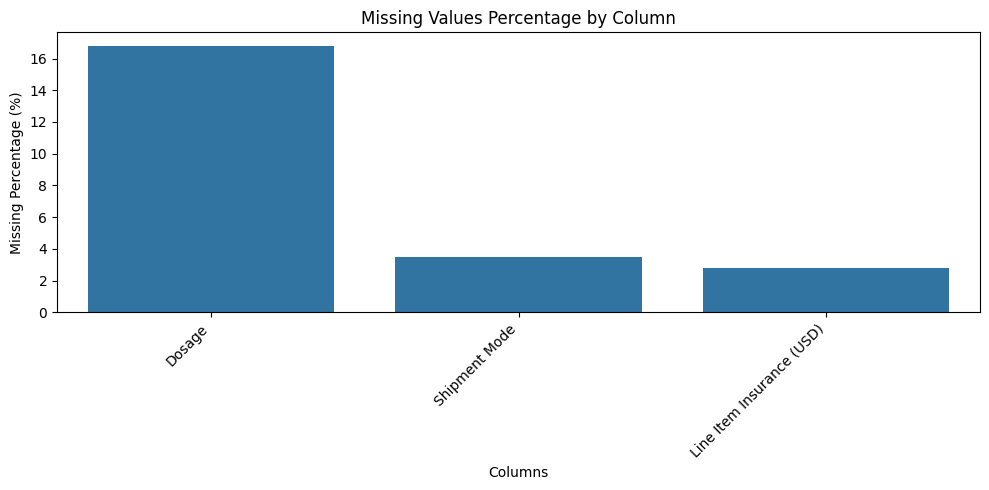

In [ ]:

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_data.index,
    y=missing_data['Missing Percentage']
)

plt.title('Missing Values Percentage by Column')
plt.xlabel('Columns')
plt.ylabel('Missing Percentage (%)')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


In [ ]:

# Check duplicate records

print("Duplicate Records:", df.duplicated().sum())

# Check data types
print("\nData Types:")
display(df.dtypes)

# Check unique shipment modes
print("\nShipment Modes:")
display(df['Shipment Mode'].value_counts(dropna=False))

# Check weight values
print("\nWeight Values:")
display(df['Weight (Kilograms)'].head(10))

# Check freight cost values
print("\nFreight Cost Values:")
display(df['Freight Cost (USD)'].head(10))


Duplicate Records: 0

Data Types:


,0
ID,int64
Project Code,object
PQ #,object
PO / SO #,object
ASN/DN #,object
Country,object
Managed By,object
Fulfill Via,object
Vendor INCO Term,object
Shipment Mode,object



Shipment Modes:


,count
Shipment Mode,
Air,6113
Truck,2830
Air Charter,650
Ocean,371
NaN,360



Weight Values:


,Weight (Kilograms)
0,13
1,358
2,171
3,1855
4,7590
5,504
6,328
7,1478
8,See ASN-93 (ID#:1281)
9,643



Freight Cost Values:


,Freight Cost (USD)
0,780.34
1,4521.5
2,1653.78
3,16007.06
4,45450.08
5,5920.42
6,Freight Included in Commodity Cost
7,6212.41
8,See ASN-93 (ID#:1281)
9,Freight Included in Commodity Cost


## 3. Data Type and Value Checks
Inspect relevant fields including shipment mode, weight, and freight cost.

In [ ]:

# Create cleaned numeric columns

df['Weight_KG_Clean'] = pd.to_numeric(
    df['Weight (Kilograms)'],
    errors='coerce'
)

df['Freight_Cost_Clean'] = pd.to_numeric(
    df['Freight Cost (USD)'],
    errors='coerce'
)

# Identify special text values
df['Weight_Reference_Flag'] = df['Weight (Kilograms)'].astype(str).str.contains(
    'See ASN',
    case=False,
    na=False
)

df['Freight_Included_Flag'] = df['Freight Cost (USD)'].astype(str).str.contains(
    'Freight Included',
    case=False,
    na=False
)

# Check results
print("Missing Weight after conversion:",
      df['Weight_KG_Clean'].isnull().sum())

print("Missing Freight Cost after conversion:",
      df['Freight_Cost_Clean'].isnull().sum())

print("Weight ASN References:",
      df['Weight_Reference_Flag'].sum())

print("Freight Included Records:",
      df['Freight_Included_Flag'].sum())

display(df[['Weight (Kilograms)',
            'Weight_KG_Clean',
            'Freight Cost (USD)',
            'Freight_Cost_Clean']].head(10))


Missing Weight after conversion: 3952
Missing Freight Cost after conversion: 4126
Weight ASN References: 508
Freight Included Records: 1442


,Weight (Kilograms),Weight_KG_Clean,Freight Cost (USD),Freight_Cost_Clean
0,13,13.0,780.34,780.34
1,358,358.0,4521.5,4521.50
2,171,171.0,1653.78,1653.78
3,1855,1855.0,16007.06,16007.06
4,7590,7590.0,45450.08,45450.08
5,504,504.0,5920.42,5920.42
6,328,328.0,Freight Included in Commodity Cost,NaN
7,1478,1478.0,6212.41,6212.41
8,See ASN-93 (ID#:1281),NaN,See ASN-93 (ID#:1281),NaN
9,643,643.0,Freight Included in Commodity Cost,NaN


## 4. Data Cleaning
Convert weight and freight fields to numeric clean columns. Preserve flags for textual values such as ASN references and “Freight Included in Commodity Cost”; these are not numeric amounts.

In [ ]:

# Identify date columns

date_columns = [
    'PQ First Sent to Client Date',
    'PO Sent to Vendor Date',
    'Scheduled Delivery Date',
    'Delivered to Client Date',
    'Delivery Recorded Date'
]

# Convert object columns into datetime
for col in date_columns:
    df[col] = pd.to_datetime(
        df[col],
        errors='coerce',
        format='mixed'
    )

# Check data types
display(df[date_columns].dtypes)

# Check missing values after conversion
display(df[date_columns].isnull().sum())


,0
PQ First Sent to Client Date,datetime64[ns]
PO Sent to Vendor Date,datetime64[ns]
Scheduled Delivery Date,datetime64[ns]
Delivered to Client Date,datetime64[ns]
Delivery Recorded Date,datetime64[ns]


,0
PQ First Sent to Client Date,2681
PO Sent to Vendor Date,5732
Scheduled Delivery Date,0
Delivered to Client Date,0
Delivery Recorded Date,0


Convert date fields to datetime. Invalid date strings become missing; assess the effect before deriving delivery metrics.

In [ ]:

# Calculate delivery delay in days

df['Delivery Delay (Days)'] = (
    df['Delivered to Client Date'] -
    df['Scheduled Delivery Date']
).dt.days

# Classify delivery status

df['Delivery Status'] = np.select(
    [
        df['Delivery Delay (Days)'] > 0,
        df['Delivery Delay (Days)'] == 0,
        df['Delivery Delay (Days)'] < 0
    ],
    [
        'Late',
        'On Time',
        'Early'
    ],
    default='Unknown'
)

# Display sample output

display(
    df[
        [
            'Scheduled Delivery Date',
            'Delivered to Client Date',
            'Delivery Delay (Days)',
            'Delivery Status'
        ]
    ].head(10)
)


,Scheduled Delivery Date,Delivered to Client Date,Delivery Delay (Days),Delivery Status
0,2006-06-02,2006-06-02,0,On Time
1,2006-11-14,2006-11-14,0,On Time
2,2006-08-27,2006-08-27,0,On Time
3,2006-09-01,2006-09-01,0,On Time
4,2006-08-11,2006-08-11,0,On Time
5,2006-09-28,2006-09-28,0,On Time
6,2007-01-08,2007-01-08,0,On Time
7,2006-11-24,2006-11-24,0,On Time
8,2006-12-07,2006-12-07,0,On Time
9,2007-01-30,2007-01-30,0,On Time


## 5. Feature Engineering — Delivery Status
Delivery delay is Delivered to Client Date minus Scheduled Delivery Date. Positive = Late, zero = On Time, negative = Early. Missing differences are Unknown.

In [ ]:

# Delivery performance summary

delivery_summary = df['Delivery Status'].value_counts()

display(delivery_summary)

# Calculate percentage

delivery_percentage = (
    df['Delivery Status'].value_counts(normalize=True) * 100
)

display(delivery_percentage.round(2))


,count
Delivery Status,
On Time,6324
Early,2814
Late,1186


,proportion
Delivery Status,
On Time,61.26
Early,27.26
Late,11.49


### 5.1 Univariate Analysis — Delivery Status
**Notebook output:** 10,324 records; 6,324 On Time (61.26%), 2,814 Early (27.26%), 1,186 Late (11.49%).

**Interpretation:** Approximately one in nine records is late using the date-difference definition. Early deliveries are distinguished from schedule adherence.

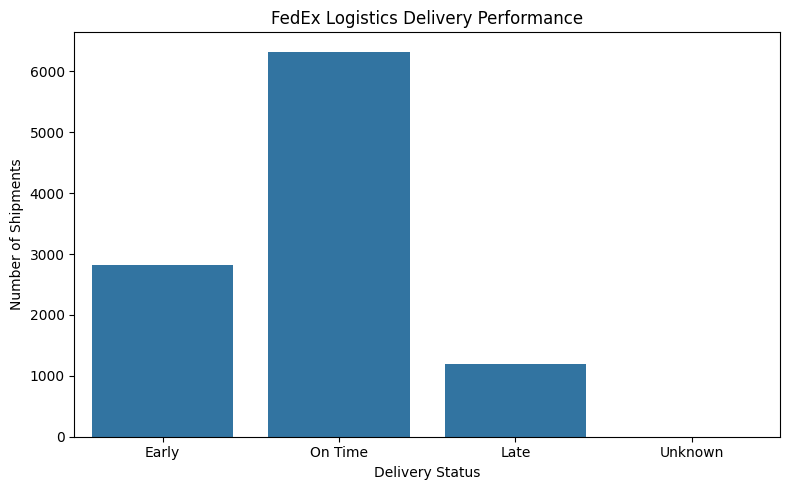

In [ ]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Delivery Status',
    order=['Early', 'On Time', 'Late', 'Unknown']
)

plt.title('FedEx Logistics Delivery Performance')
plt.xlabel('Delivery Status')
plt.ylabel('Number of Shipments')

plt.tight_layout()
plt.show()


In [ ]:

# Analyze shipment performance by mode

mode_analysis = df.dropna(subset=['Shipment Mode']).groupby(
    'Shipment Mode'
).agg(
    Total_Shipments=('ID', 'count'),
    Late_Shipments=('Delivery Status', lambda x: (x == 'Late').sum()),
    On_Time_Shipments=('Delivery Status', lambda x: (x == 'On Time').sum()),
    Average_Delay=('Delivery Delay (Days)', 'mean')
).reset_index()

# Calculate late delivery rate

mode_analysis['Late_Rate (%)'] = (
    mode_analysis['Late_Shipments'] /
    mode_analysis['Total_Shipments'] * 100
)

display(mode_analysis)


,Shipment Mode,Total_Shipments,Late_Shipments,On_Time_Shipments,Average_Delay,Late_Rate (%)
0,Air,6113,587,4343,-3.763782,9.602487
1,Air Charter,650,75,123,-19.036923,11.538462
2,Ocean,371,65,291,5.870620,17.520216
3,Truck,2830,455,1238,-9.921908,16.077739


## 6. Bivariate Analysis — Shipment Mode
Compare counts, late deliveries, on-time deliveries, average delay, and late rate. Read percentages alongside shipment counts.

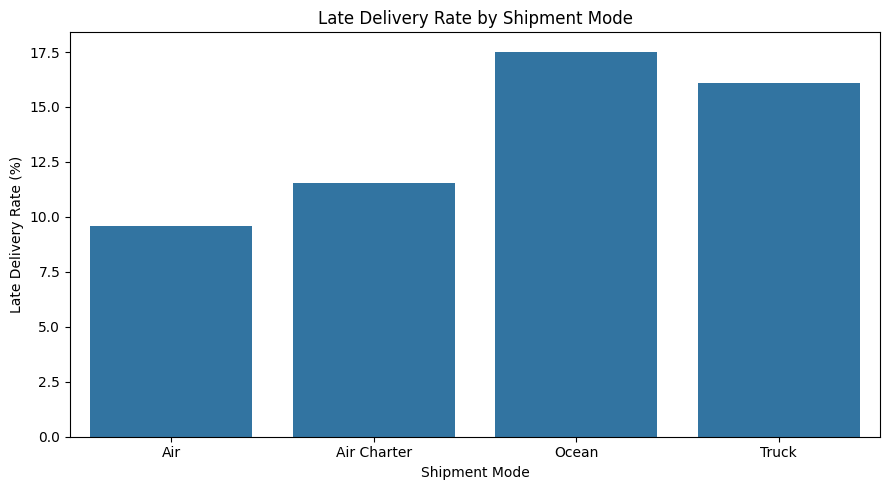

In [ ]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=mode_analysis,
    x='Shipment Mode',
    y='Late_Rate (%)'
)

plt.title('Late Delivery Rate by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Late Delivery Rate (%)')

plt.tight_layout()
plt.show()


### Interpretation
Observed late rates: Air 9.60%, Air Charter 11.54%, Ocean 17.52%, Truck 16.08%. Ocean and Truck have comparatively higher observed late rates than Air. This is descriptive; mode may be associated with route and shipment characteristics.

In [ ]:
"""
Step 5: Continue with Country-wise Analysis
5.1 Top 15 countries by shipment volume
"""

'\nStep 5: Continue with Country-wise Analysis\n5.1 Top 15 countries by shipment volume\n'

## 7. Country-wise Delivery Analysis
Shipment volume is analyzed to provide context for country-level performance.

In [ ]:

country_analysis = df.groupby('Country').agg(
    Total_Shipments=('ID', 'count'),
    Late_Shipments=('Delivery Status',
                   lambda x: (x == 'Late').sum()),
    On_Time_Shipments=('Delivery Status',
                       lambda x: (x == 'On Time').sum())
).reset_index()

country_analysis['Late_Rate (%)'] = (
    country_analysis['Late_Shipments'] /
    country_analysis['Total_Shipments'] * 100
)

top_countries = country_analysis.sort_values(
    'Total_Shipments',
    ascending=False
).head(15)

display(top_countries)


,Country,Total_Shipments,Late_Shipments,On_Time_Shipments,Late_Rate (%)
33,South Africa,1406,115,1013,8.179232
28,Nigeria,1194,142,495,11.892797
9,Côte d'Ivoire,1083,134,600,12.373038
39,Uganda,779,98,384,12.580231
40,Vietnam,688,6,666,0.872093
41,Zambia,683,108,369,15.812592
16,Haiti,655,62,476,9.465649
26,Mozambique,631,116,366,18.383518
42,Zimbabwe,538,77,234,14.312268
37,Tanzania,519,66,315,12.716763


Country-level late rates are computed. Interpret rates with shipment counts; low-volume countries can produce unstable percentages.

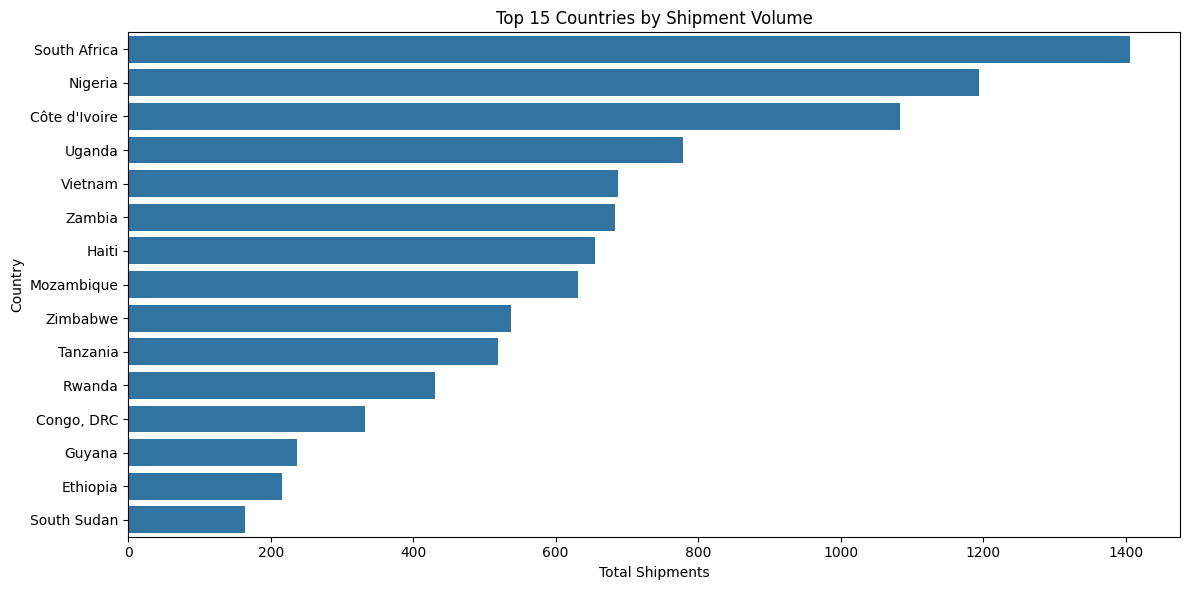

In [ ]:
#5.2 Visualize shipment volume

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x='Total_Shipments',
    y='Country'
)

plt.title('Top 15 Countries by Shipment Volume')
plt.xlabel('Total Shipments')
plt.ylabel('Country')

plt.tight_layout()
plt.show()


### 7.1 Shipment Volume by Country
High-volume destinations are candidates for monitoring due to their shipment activity.

,Country,Total_Shipments,Late_Shipments,On_Time_Shipments,Late_Rate (%)
6,Burundi,98,38,28,38.775510
31,Senegal,3,1,2,33.333333
38,Togo,3,1,1,33.333333
8,"Congo, DRC",333,83,170,24.924925
3,Benin,13,3,3,23.076923
26,Mozambique,631,116,366,18.383518
41,Zambia,683,108,369,15.812592
42,Zimbabwe,538,77,234,14.312268
12,Ghana,58,8,42,13.793103
13,Guatemala,15,2,8,13.333333


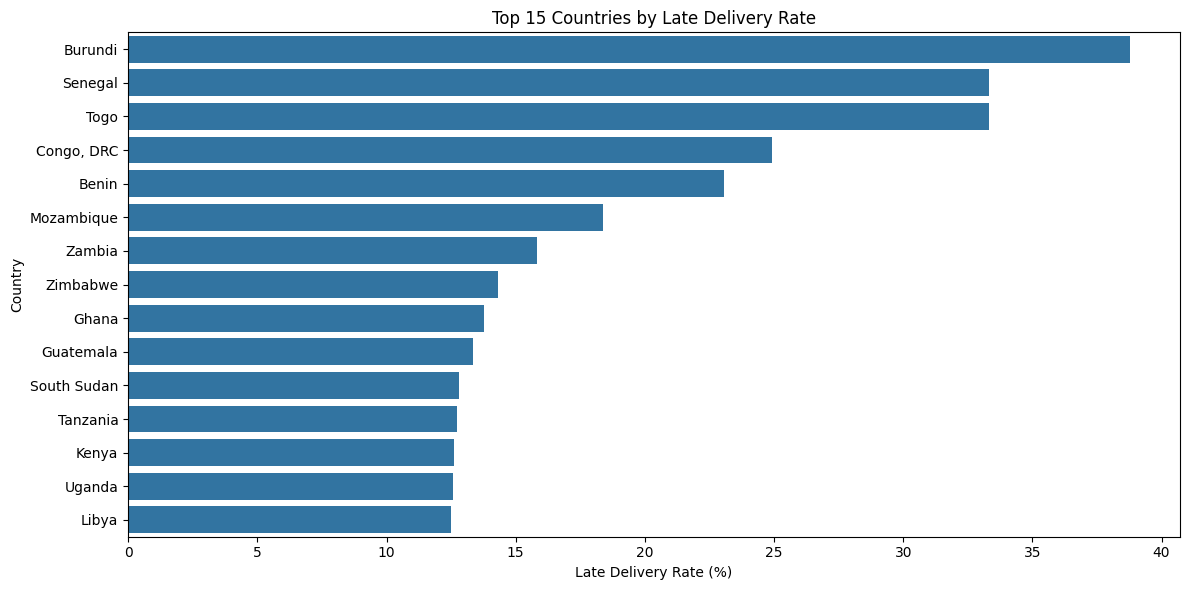

In [ ]:
#Step 5.3: Analyze late delivery rates by country

# Sort countries by late delivery rate
top_late_countries = country_analysis.sort_values(
    by='Late_Rate (%)',
    ascending=False
).head(15)

display(top_late_countries)

# Plot late delivery rate
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_late_countries,
    x='Late_Rate (%)',
    y='Country'
)

plt.title('Top 15 Countries by Late Delivery Rate')
plt.xlabel('Late Delivery Rate (%)')
plt.ylabel('Country')

plt.tight_layout()
plt.show()


### 7.2 Late Delivery Rate by Country
High-rate countries are investigation candidates, not definitive rankings. Consider minimum shipment counts and route/mode mix.

In [ ]:
#Step 6: Freight Cost Analysis
#Analyze freight expenses across shipment modes.
#6.1 Freight cost summary

## 8. Freight Cost Analysis
Numeric freight values are analyzed. Text entries (including freight-included entries and ASN references) are excluded from numeric totals, not assumed to be zero.

In [ ]:

# Freight cost analysis by shipment mode

freight_analysis = df.groupby('Shipment Mode').agg(
    Total_Shipments=('ID', 'count'),

    Total_Freight_Cost=('Freight_Cost_Clean', 'sum'),

    Average_Freight_Cost=('Freight_Cost_Clean', 'mean'),

    Median_Freight_Cost=('Freight_Cost_Clean', 'median')
).reset_index()

display(freight_analysis.round(2))


,Shipment Mode,Total_Shipments,Total_Freight_Cost,Average_Freight_Cost,Median_Freight_Cost
0,Air,6113,43038623.50,10458.96,4764.16
1,Air Charter,650,8926108.48,21052.14,15322.73
2,Ocean,371,3590728.79,12733.08,9520.98
3,Truck,2830,11865688.23,10176.41,5985.84


### 8.1 Freight Summary by Shipment Mode
Mean and median are reported alongside totals because freight distributions can be skewed.

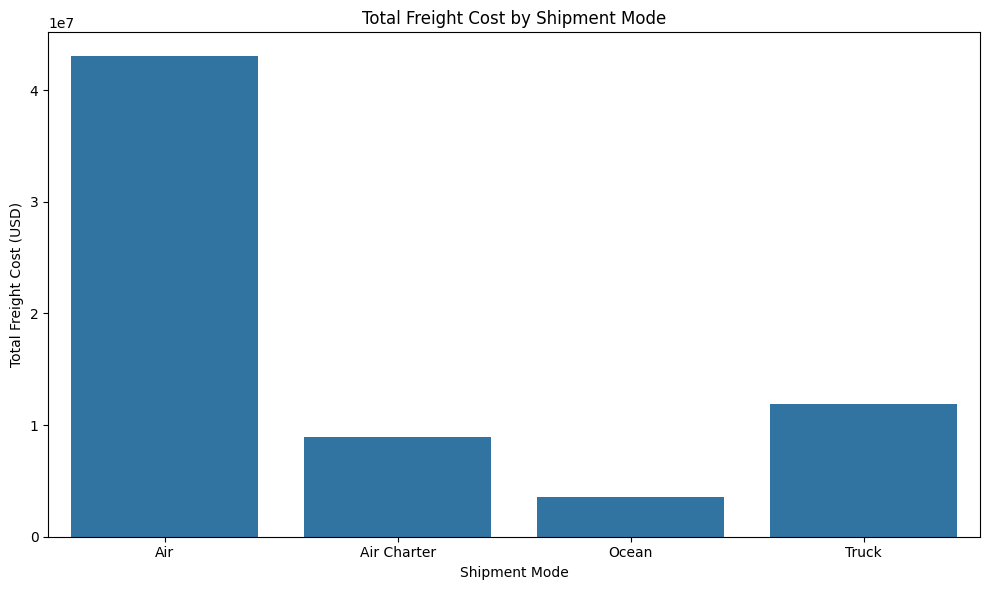

In [ ]:
#6.2 Visualize total freight cost

plt.figure(figsize=(10, 6))

sns.barplot(
    data=freight_analysis,
    x='Shipment Mode',
    y='Total_Freight_Cost'
)

plt.title('Total Freight Cost by Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Total Freight Cost (USD)')

plt.tight_layout()
plt.show()


### 8.2 Total Freight Cost
Air has the largest recorded numeric freight total (approximately USD 43.04 million) and the largest shipment count. Total expenditure alone does not indicate cost efficiency.

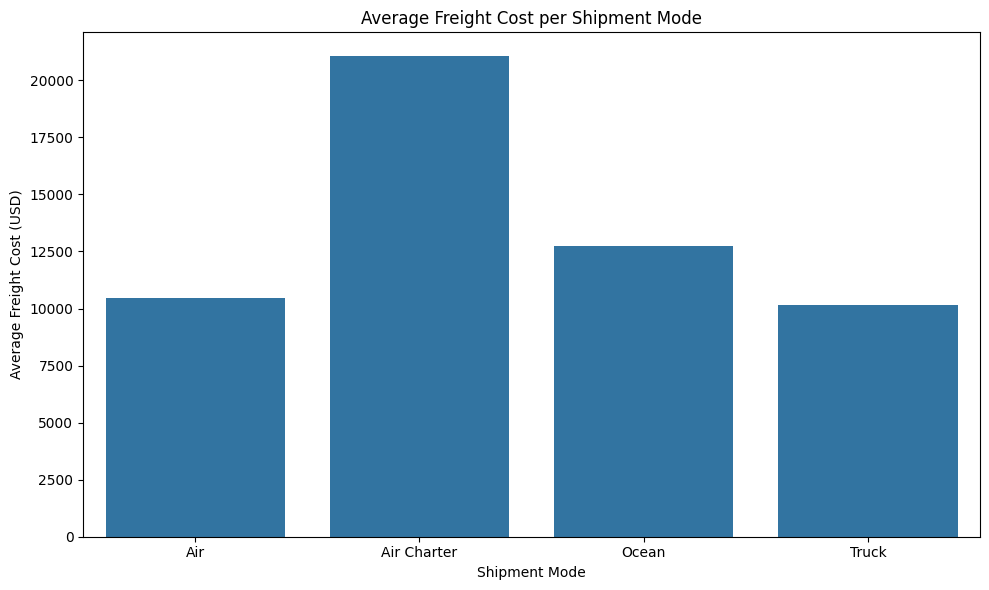

In [ ]:
#6.3 Analyze average freight cost

plt.figure(figsize=(10, 6))

sns.barplot(
    data=freight_analysis,
    x='Shipment Mode',
    y='Average_Freight_Cost'
)

plt.title('Average Freight Cost per Shipment Mode')
plt.xlabel('Shipment Mode')
plt.ylabel('Average Freight Cost (USD)')

plt.tight_layout()
plt.show()


### 8.3 Average Freight Cost
Air Charter has the highest average recorded cost per shipment (approximately USD 21,052); Truck is approximately USD 10,176. Values may reflect route, distance, shipment size, and urgency.

In [ ]:
#Step 6.4: Analyze Freight Cost as a Percentage of Shipment Value

# Freight cost as a percentage of line item value

df['Freight_to_Item_Value (%)'] = (
    df['Freight_Cost_Clean'] /
    df['Line Item Value'].replace(0, np.nan)
) * 100

# Analyze by shipment mode

freight_ratio = df.groupby('Shipment Mode').agg(
    Average_Freight_Ratio=('Freight_to_Item_Value (%)', 'mean'),
    Median_Freight_Ratio=('Freight_to_Item_Value (%)', 'median')
).reset_index()

display(freight_ratio.round(2))


,Shipment Mode,Average_Freight_Ratio,Median_Freight_Ratio
0,Air,3571.76,12.61
1,Air Charter,1441.25,8.73
2,Ocean,43.28,3.48
3,Truck,346.89,5.89


### 8.4 Record-level Freight-to-Item Value Ratio
This mean ratio may be highly skewed and sensitive to small item values or missing freight data. Treat as diagnostic; the aggregate ratio below is more interpretable.

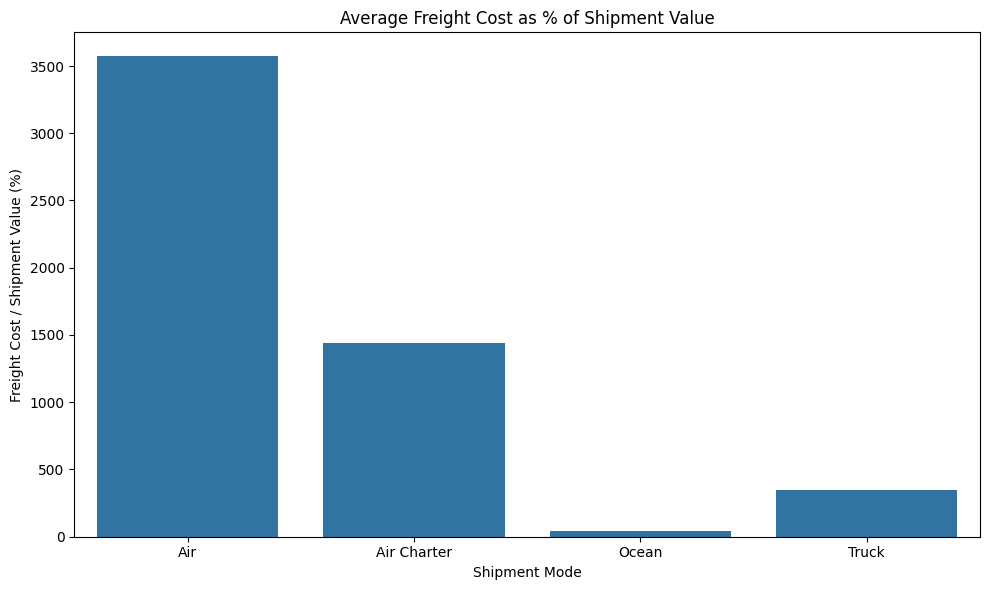

In [ ]:
#Visualize

plt.figure(figsize=(10, 6))

sns.barplot(
    data=freight_ratio,
    x='Shipment Mode',
    y='Average_Freight_Ratio'
)

plt.title('Average Freight Cost as % of Shipment Value')
plt.xlabel('Shipment Mode')
plt.ylabel('Freight Cost / Shipment Value (%)')

plt.tight_layout()
plt.show()


In [ ]:
#Step 6.5: Calculate a more reliable freight cost ratio


# Calculate total freight cost relative to total shipment value

freight_value_analysis = df.groupby('Shipment Mode').agg(
    Total_Freight_Cost=('Freight_Cost_Clean', 'sum'),
    Total_Shipment_Value=('Line Item Value', 'sum')
).reset_index()

freight_value_analysis['Freight Cost Ratio (%)'] = (
    freight_value_analysis['Total_Freight_Cost'] /
    freight_value_analysis['Total_Shipment_Value']
) * 100

display(freight_value_analysis.round(2))


,Shipment Mode,Total_Freight_Cost,Total_Shipment_Value,Freight Cost Ratio (%)
0,Air,43038623.50,6.272859e+08,6.86
1,Air Charter,8926108.48,2.463722e+08,3.62
2,Ocean,3590728.79,1.261779e+08,2.85
3,Truck,11865688.23,5.873824e+08,2.02


### 8.5 Aggregate Freight Cost Ratio
Calculated as total numeric freight cost divided by total item value. Output: Air 6.86%, Air Charter 3.62%, Ocean 2.85%, Truck 2.02%. These are descriptive and not like-for-like efficiency measures.

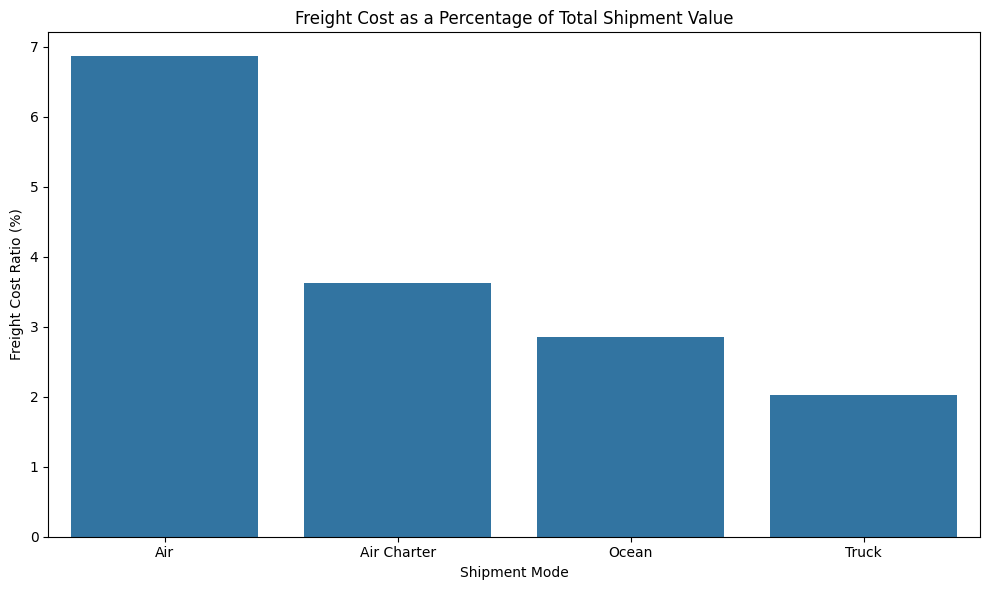

In [ ]:
#Correct Visulaization

plt.figure(figsize=(10, 6))

sns.barplot(
    data=freight_value_analysis,
    x='Shipment Mode',
    y='Freight Cost Ratio (%)'
)

plt.title('Freight Cost as a Percentage of Total Shipment Value')
plt.xlabel('Shipment Mode')
plt.ylabel('Freight Cost Ratio (%)')

plt.tight_layout()
plt.show()


In [ ]:
#Step 7: Final Project KPI Summary

## 9. Logistics KPI Summary
The KPI table consolidates delivery outcomes and numeric freight cost metrics.

In [ ]:

# Overall Logistics KPIs

total_shipments = len(df)

late_shipments = (df['Delivery Status'] == 'Late').sum()

on_time_shipments = (df['Delivery Status'] == 'On Time').sum()

early_shipments = (df['Delivery Status'] == 'Early').sum()

late_delivery_rate = (late_shipments / total_shipments) * 100

on_time_delivery_rate = (on_time_shipments / total_shipments) * 100

early_delivery_rate = (early_shipments / total_shipments) * 100

average_delivery_delay = df.loc[
    df['Delivery Status'] == 'Late',
    'Delivery Delay (Days)'
].mean()

total_freight_cost = df['Freight_Cost_Clean'].sum()

total_shipment_value = df['Line Item Value'].sum()

freight_cost_ratio = (
    total_freight_cost / total_shipment_value
) * 100

# Display KPI summary

kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Shipments',
        'Late Shipments',
        'On-Time Shipments',
        'Early Shipments',
        'Late Delivery Rate (%)',
        'On-Time Delivery Rate (%)',
        'Early Delivery Rate (%)',
        'Average Delay for Late Shipments (Days)',
        'Total Freight Cost (USD)',
        'Freight Cost Ratio (%)'
    ],

    'Value': [
        total_shipments,
        late_shipments,
        on_time_shipments,
        early_shipments,
        round(late_delivery_rate, 2),
        round(on_time_delivery_rate, 2),
        round(early_delivery_rate, 2),
        round(average_delivery_delay, 2),
        round(total_freight_cost, 2),
        round(freight_cost_ratio, 2)
    ]
})

display(kpi_summary)


,KPI,Value
0,Total Shipments,10324.00
1,Late Shipments,1186.00
2,On-Time Shipments,6324.00
3,Early Shipments,2814.00
4,Late Delivery Rate (%),11.49
5,On-Time Delivery Rate (%),61.26
6,Early Delivery Rate (%),27.26
7,Average Delay for Late Shipments (Days),21.37
8,Total Freight Cost (USD),68817849.41
9,Freight Cost Ratio (%),4.23


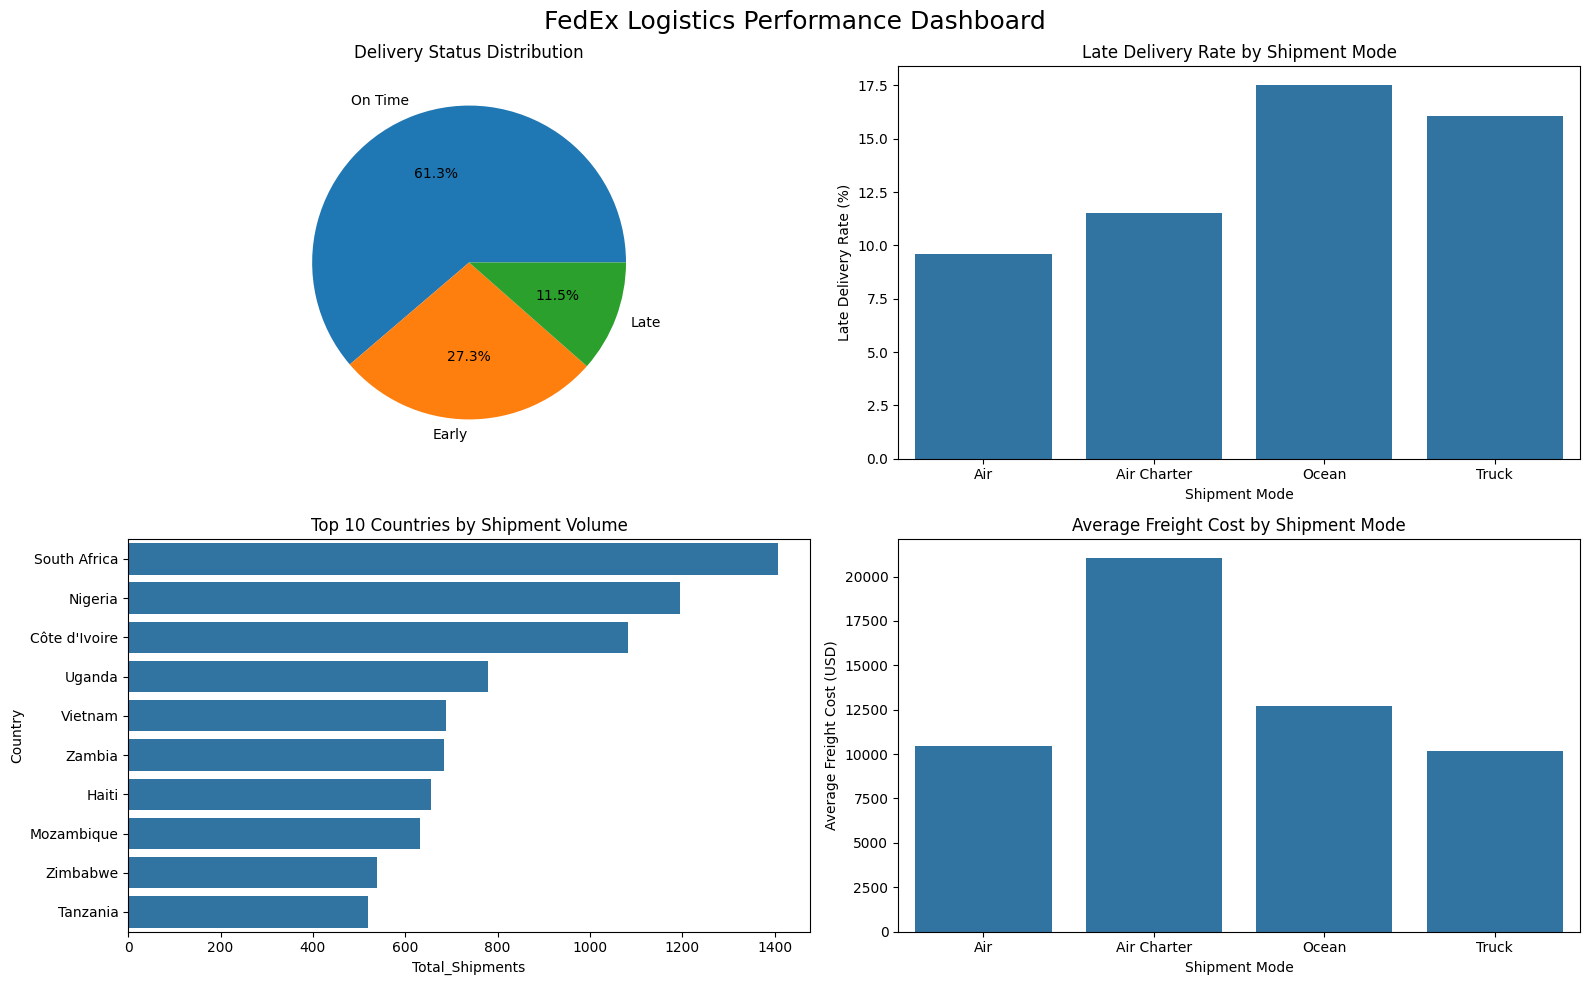

In [ ]:
#Create the final consolidated dashboard.
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Delivery Status Distribution
df['Delivery Status'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[0, 0]
)

axes[0, 0].set_title('Delivery Status Distribution')
axes[0, 0].set_ylabel('')

# 2. Late Delivery Rate by Shipment Mode
sns.barplot(
    data=mode_analysis,
    x='Shipment Mode',
    y='Late_Rate (%)',
    ax=axes[0, 1]
)

axes[0, 1].set_title('Late Delivery Rate by Shipment Mode')
axes[0, 1].set_ylabel('Late Delivery Rate (%)')

# 3. Top 10 Countries by Shipment Volume
top_10_countries = country_analysis.sort_values(
    'Total_Shipments',
    ascending=False
).head(10)

sns.barplot(
    data=top_10_countries,
    x='Total_Shipments',
    y='Country',
    ax=axes[1, 0]
)

axes[1, 0].set_title('Top 10 Countries by Shipment Volume')

# 4. Average Freight Cost by Shipment Mode
sns.barplot(
    data=freight_analysis,
    x='Shipment Mode',
    y='Average_Freight_Cost',
    ax=axes[1, 1]
)

axes[1, 1].set_title('Average Freight Cost by Shipment Mode')
axes[1, 1].set_ylabel('Average Freight Cost (USD)')

# Main Dashboard Title
plt.suptitle(
    'FedEx Logistics Performance Dashboard',
    fontsize=18
)

plt.tight_layout()

plt.savefig(
    'FedEx_Logistics_Dashboard.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## 10. Consolidated Dashboard
The dashboard provides an overview of delivery status, shipment-mode late rates, destination performance, and freight indicators. Use preceding analysis for context.

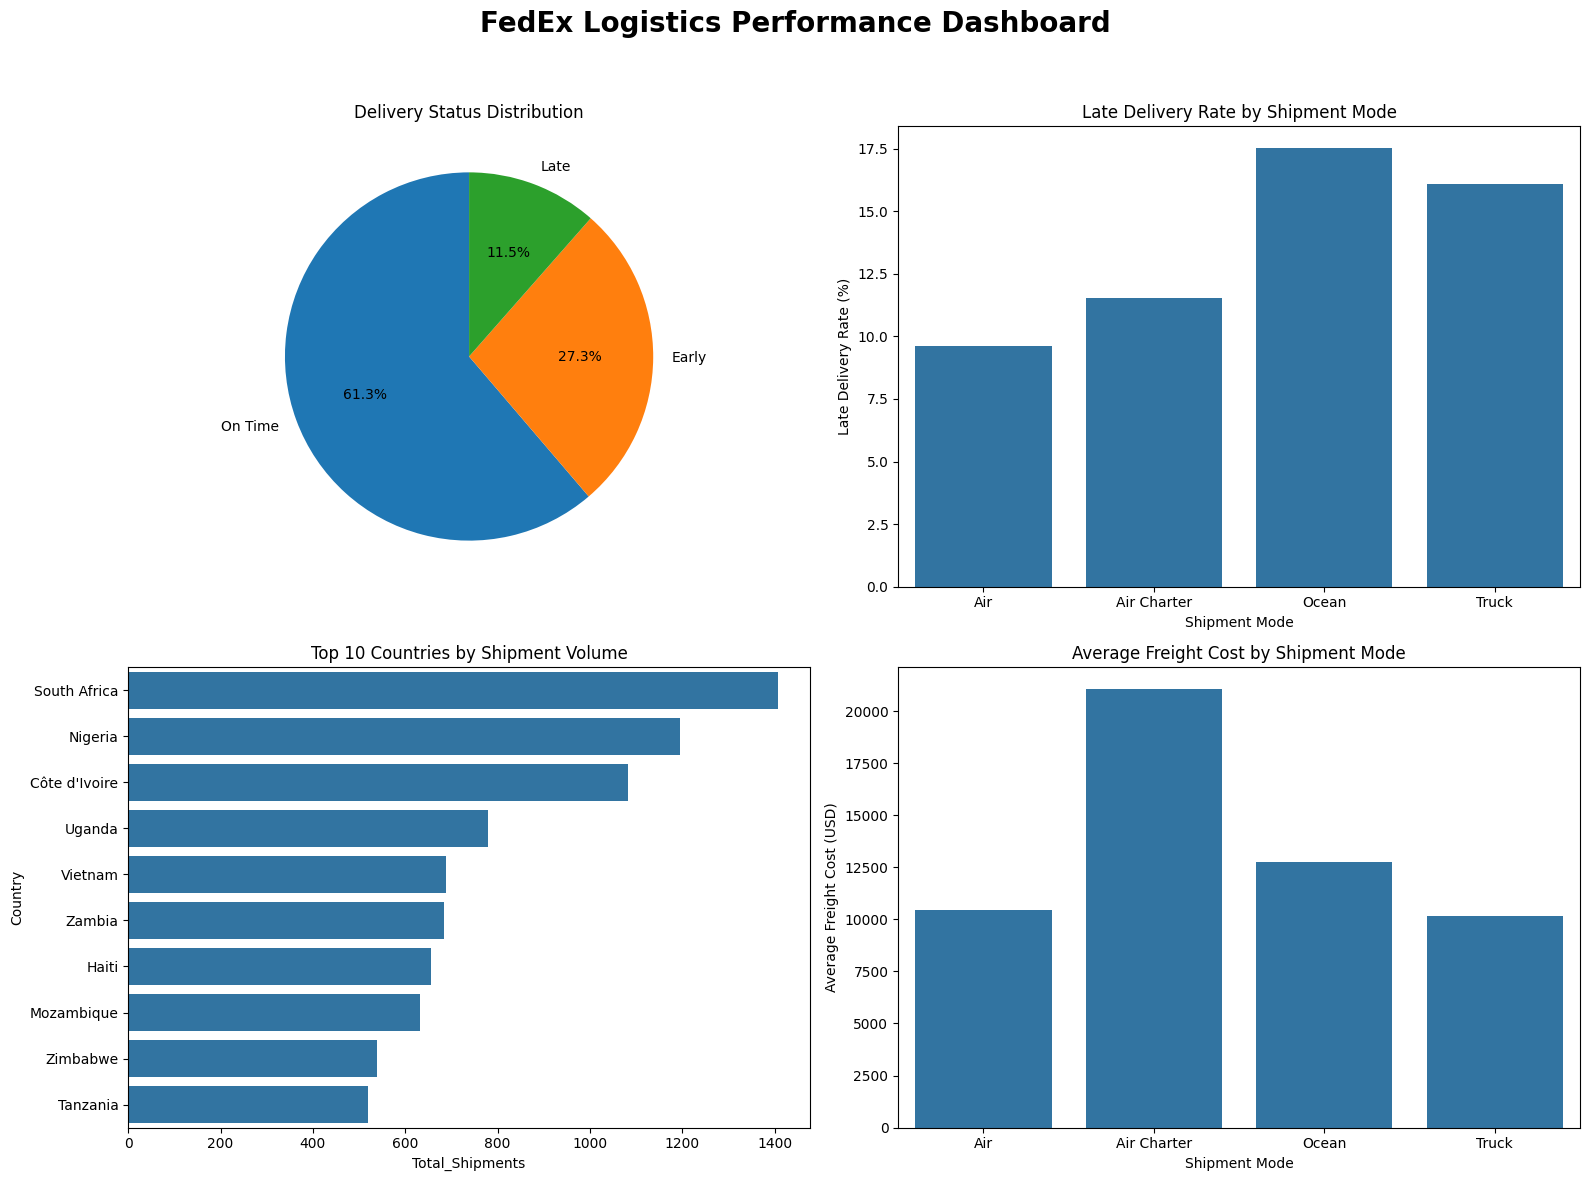

In [ ]:
#Improve Dashboard

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Delivery Status Distribution
df['Delivery Status'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Delivery Status Distribution')
axes[0, 0].set_ylabel('')

# 2. Late Delivery Rate by Shipment Mode
sns.barplot(
    data=mode_analysis,
    x='Shipment Mode',
    y='Late_Rate (%)',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Late Delivery Rate by Shipment Mode')
axes[0, 1].set_ylabel('Late Delivery Rate (%)')

# 3. Top 10 Countries by Shipment Volume
sns.barplot(
    data=top_10_countries,
    x='Total_Shipments',
    y='Country',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Top 10 Countries by Shipment Volume')

# 4. Average Freight Cost by Shipment Mode
sns.barplot(
    data=freight_analysis,
    x='Shipment Mode',
    y='Average_Freight_Cost',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Average Freight Cost by Shipment Mode')
axes[1, 1].set_ylabel('Average Freight Cost (USD)')

# Dashboard title
fig.suptitle(
    'FedEx Logistics Performance Dashboard',
    fontsize=20,
    fontweight='bold',
    y=0.98
)

# Leave space for title
plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save high-quality image
plt.savefig(
    'FedEx_Logistics_Dashboard.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## 11. Key Findings and Business Recommendations

### Key findings from the notebook outputs
- Dataset: 10,324 shipment rows and 33 columns; zero exact duplicate rows.
- Delivery outcomes: 61.26% On Time, 27.26% Early, 11.49% Late.
- Late rates by mode: Air 9.60%, Air Charter 11.54%, Ocean 17.52%, Truck 16.08%.
- Air has the largest recorded numeric freight total (about USD 43.04 million), alongside the largest shipment volume.
- Aggregate freight-to-item-value ratios: Air 6.86%, Air Charter 3.62%, Ocean 2.85%, Truck 2.02%.

### Recommendations
1. Investigate Ocean and Truck delays by route, destination, vendor, and planned transit time.
2. Monitor high-volume destinations alongside their late rates; establish a minimum volume before country ranking.
3. Assess Air freight cost with shipment volume, size, route distance, and service urgency considered.
4. Classify special textual weight/freight values rather than converting them to zero.
5. Monitor delivery outcome, late rate, median delay, and aggregate freight ratio in a recurring dashboard.

## 12. Hypotheses and Assumptions
- **H1:** Observed late-delivery rates vary across shipment modes.
- **H2:** Shipment volumes vary across countries.
- **H3:** Aggregate freight-cost-to-item-value ratios vary across shipment modes.
- **H4:** Country delivery outcomes may vary; volume and mode mix need consideration.

These are explored descriptively. No inferential statistical tests are performed; statistical significance is not claimed.

### Assumptions and limitations
- Delivery status uses Delivered to Client Date compared with Scheduled Delivery Date.
- The data is historical and may not represent current logistics performance.
- Numeric freight totals exclude unparseable text values and ASN references.
- Mode/country comparisons may be confounded by route, vendor, product, shipment value, or shipment size.
- The project does not establish causation or build a predictive model.

## 13. Conclusion
This analysis summarizes delivery and recorded freight-cost patterns. On-time shipments account for 61.26%, while 11.49% are classified late. Ocean and Truck show higher observed late rates than Air, and aggregate freight ratios differ by mode. These findings can prioritize operational review, but should be validated with route, vendor, shipment-size, and time-based analysis before decisions are made.

## 14. Future Scope
- Examine delay trends over time and by route/vendor.
- Apply appropriate statistical tests to delivery-rate differences.
- Build a Power BI or interactive Plotly dashboard.
- Explore delay prediction with leakage controls and time-aware validation.

## 15. GitHub Repository
**Repository URL:https://github.com/anamika-2408/FedEx-Logistics-Performance-Analysis/upload/main
